# Optimización del tamaño de paquete (MTU) en redes
**Cálculo Diferencial — Proyecto Final, Tema 15 · Universidad de La Salle**

Este notebook reproduce todos los resultados del artículo:

1. Modelo de eficiencia $E(S)$ con encabezado fijo $H$ y probabilidad de retransmisión $P(S)$.
2. Tamaño óptimo $S^*$ a partir de $dE/dS = 0$ y verificación con la segunda derivada.
3. Simulación Monte Carlo con barras de error.
4. Sensibilidad frente a la tasa de error de bit (BER) y al encabezado.
5. Propagación de la incertidumbre de la BER hacia $S^*$.

Todas las figuras se guardan en `figuras/` y las tablas en `resultados/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 2026                       # semilla fija -> resultados 100 % reproducibles
rng = np.random.default_rng(SEED)
Path("figuras").mkdir(exist_ok=True)
Path("resultados").mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
H = 40.0   # encabezado TCP/IPv4 en bytes (20 IP + 20 TCP)

## 1. Modelo

Un paquete tiene $S$ bytes de datos útiles (payload) y $H$ bytes de encabezado. Si cada bit se corrompe de forma independiente con probabilidad $p$ (BER), el paquete llega intacto con probabilidad

$$1-P(S) = (1-p)^{8(S+H)} = e^{-\beta (S+H)}, \qquad \beta = -8\ln(1-p) \approx 8p .$$

Un paquete corrupto se retransmite, así que el número esperado de envíos es $1/(1-P)$. La eficiencia (fracción de bytes enviados que son datos útiles entregados) es

$$E(S) = \frac{S}{S+H}\,e^{-\beta(S+H)} .$$

In [2]:
def beta_de(p):
    # constante de decaimiento por byte: (1-p)^(8n) = exp(-beta n)
    return -8.0 * np.log1p(-p)

def eficiencia(S, beta, H=H):
    return S / (S + H) * np.exp(-beta * (S + H))

def dE_dS(S, beta, H=H):
    # derivada analítica (regla del producto + cadena), ver Apéndice A
    return np.exp(-beta * (S + H)) * (H / (S + H)**2 - beta * S / (S + H))

def S_optimo(beta, H=H):
    # raíz positiva de beta S^2 + beta H S - H = 0
    return (-H + np.sqrt(H**2 + 4 * H / beta)) / 2

def S_aprox(beta, H=H):
    # aproximación para beta*H << 1
    return np.sqrt(H / beta)

## 2. Tamaño óptimo y verificación

Se compara la fórmula cerrada de $S^*$ con: (i) la búsqueda numérica del máximo en una malla fina y (ii) el método de Newton-Raphson aplicado a $dE/dS=0$. También se evalúa la segunda derivada en $S^*$ para confirmar que es un máximo.

In [3]:
def d2E_num(S, beta, h=1e-2):
    return (eficiencia(S+h, beta) - 2*eficiencia(S, beta) + eficiencia(S-h, beta)) / h**2

def newton_dEdS(beta, S0=None, tol=1e-10, maxit=50):
    # Se arranca en sqrt(H/beta): desde un punto lejano Newton puede caer en la
    # raíz negativa de la cuadrática, que no tiene sentido físico.
    S, h = (S_aprox(beta) if S0 is None else S0), 1e-3
    for k in range(1, maxit + 1):
        g  = dE_dS(S, beta)
        dg = (dE_dS(S + h, beta) - dE_dS(S - h, beta)) / (2 * h)
        S_new = S - g / dg
        if abs(S_new - S) < tol:
            return S_new, k
        S = S_new
    return S, maxit

BERs = [1e-4, 1e-5, 1e-6, 1e-7]
malla = np.linspace(1, 50_000, 2_000_001)
filas = []
for p in BERs:
    b = beta_de(p)
    s_cf = S_optimo(b)
    s_num = malla[np.argmax(eficiencia(malla, b))]
    s_nr, it = newton_dEdS(b)
    filas.append((p, b, s_cf, s_num, s_nr, it, S_aprox(b),
                  eficiencia(s_cf, b), eficiencia(1500, b), d2E_num(s_cf, b)))

print(f"{'BER':>7} {'beta':>9} {'S* cerrada':>11} {'S* malla':>9} {'S* Newton':>10} {'it':>3} "
      f"{'sqrt(H/b)':>10} {'E(S*)':>7} {'E(1500)':>8} {'d2E/dS2':>10}")
for f in filas:
    print(f"{f[0]:7.0e} {f[1]:9.2e} {f[2]:11.1f} {f[3]:9.1f} {f[4]:10.1f} {f[5]:3d} "
          f"{f[6]:10.1f} {f[7]:7.4f} {f[8]:8.4f} {f[9]:10.2e}")

np.savetxt("resultados/tabla_optimos.csv", np.array(filas), delimiter=",",
           header="BER,beta,S_cerrada,S_malla,S_newton,iter,S_aprox,E_opt,E_1500,d2E",
           comments="")

    BER      beta  S* cerrada  S* malla  S* Newton  it  sqrt(H/b)   E(S*)  E(1500)    d2E/dS2
  1e-04  8.00e-04       204.5     204.5      204.5   5      223.6  0.6878   0.2841  -4.94e-06
  1e-05  8.00e-05       687.4     687.4      687.4   5      707.1  0.8916   0.8611  -2.02e-07
  1e-06  8.00e-06      2216.2    2216.2     2216.2   4     2236.1  0.9647   0.9621  -6.90e-09
  1e-07  8.00e-07      7051.1    7051.1     7051.1   4     7071.1  0.9887   0.9728  -2.24e-10


## 3. Curvas de eficiencia (Figura 1)

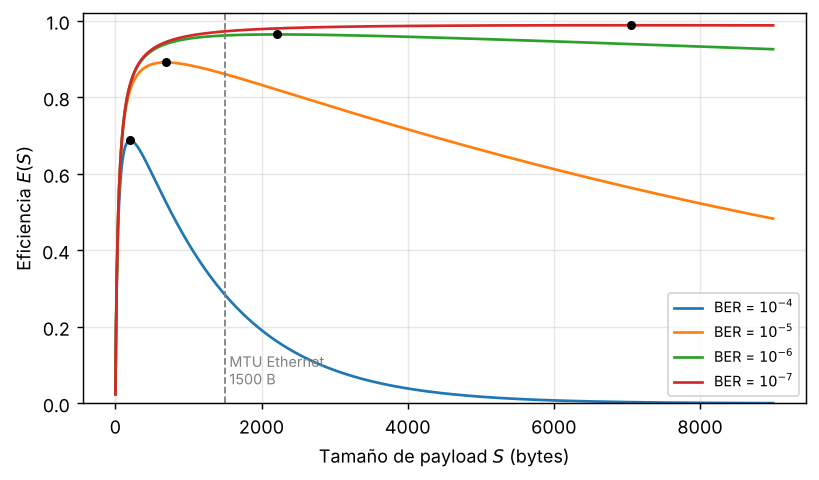

In [4]:
S = np.linspace(1, 9000, 4000)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for p in BERs:
    b = beta_de(p)
    ax.plot(S, eficiencia(S, b), label=f"BER = $10^{{{int(np.log10(p))}}}$")
    so = S_optimo(b)
    if so < S.max():
        ax.plot(so, eficiencia(so, b), "ko", ms=4)
ax.axvline(1500, ls="--", c="gray", lw=1)
ax.text(1560, 0.05, "MTU Ethernet\n1500 B", fontsize=8, color="gray")
ax.set_xlabel("Tamaño de payload $S$ (bytes)")
ax.set_ylabel("Eficiencia $E(S)$")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figuras/fig1_eficiencia.png", dpi=200)
plt.show()

## 4. Simulación Monte Carlo con barras de error (Figura 2)

Para validar el modelo de forma independiente se simula la transmisión real: para cada tamaño $S$ se envían $N$ paquetes; el número de intentos hasta el éxito de cada paquete es una variable geométrica con probabilidad de éxito $e^{-\beta(S+H)}$. La eficiencia medida es (bytes útiles entregados)/(bytes totales enviados). Se repite $R$ veces para obtener media y desviación estándar.

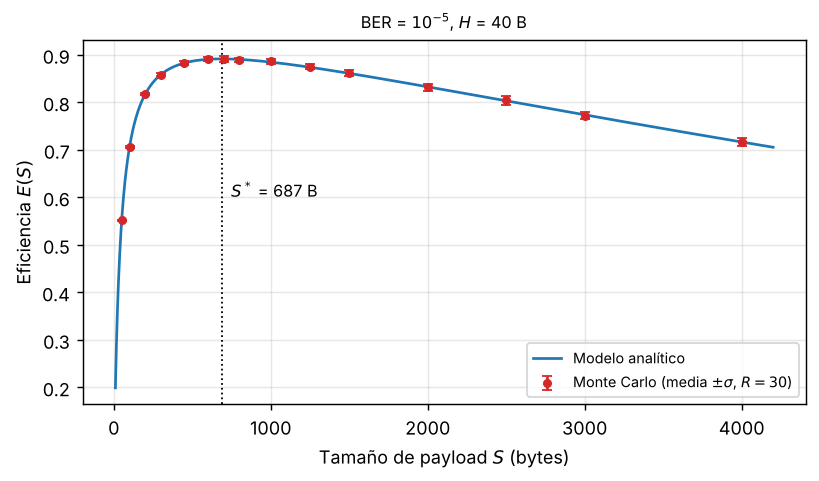

Desviación máxima |MC - teoría| / sigma = 0.26
Fracción de puntos dentro de 1 sigma   = 1.0


In [5]:
def eficiencia_mc(S, p, N=2000, R=30, rng=rng):
    q = (1 - p) ** (8 * (S + H))          # prob. de que el paquete llegue intacto
    medidas = np.empty(R)
    for r in range(R):
        intentos = rng.geometric(q, size=N)   # envíos hasta el primer éxito
        medidas[r] = (N * S) / (intentos.sum() * (S + H))
    return medidas.mean(), medidas.std(ddof=1)

p_ref = 1e-5
b_ref = beta_de(p_ref)
S_mc = np.array([50, 100, 200, 300, 450, 600, 700, 800, 1000, 1250, 1500,
                 2000, 2500, 3000, 4000])
mc = np.array([eficiencia_mc(s, p_ref) for s in S_mc])

S_fino = np.linspace(10, 4200, 2000)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(S_fino, eficiencia(S_fino, b_ref), "C0", label="Modelo analítico")
ax.errorbar(S_mc, mc[:, 0], yerr=mc[:, 1], fmt="o", ms=4, capsize=3,
            color="C3", label="Monte Carlo (media $\\pm\\sigma$, $R=30$)")
so = S_optimo(b_ref)
ax.axvline(so, ls=":", c="k", lw=1)
ax.text(so + 60, 0.60, f"$S^*$ = {so:.0f} B", fontsize=9)
ax.set_xlabel("Tamaño de payload $S$ (bytes)")
ax.set_ylabel("Eficiencia $E(S)$")
ax.set_title("BER = $10^{-5}$, $H$ = 40 B", fontsize=9)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figuras/fig2_montecarlo.png", dpi=200)
plt.show()

teo = eficiencia(S_mc, b_ref)
z = (mc[:, 0] - teo) / mc[:, 1]
print("Desviación máxima |MC - teoría| / sigma =", np.abs(z).max().round(2))
print("Fracción de puntos dentro de 1 sigma   =", np.mean(np.abs(z) < 1).round(2))
np.savetxt("resultados/montecarlo.csv",
           np.column_stack([S_mc, mc, teo]), delimiter=",",
           header="S,E_mc_media,E_mc_sigma,E_teoria", comments="")

### Estimación experimental de $S^*$ a partir de la simulación

Primero se intentó ajustar una parábola cerca del máximo, pero $E(S)$ es **asimétrica** (cae rápido a la izquierda y lento a la derecha) y el vértice sale sesgado. Es mejor **linealizar** el modelo: tomando logaritmo,

$$y \equiv \ln E - \ln S + \ln(S+H) = -\beta\,(S+H),$$

que es una recta en $x=S+H$ de pendiente $-\beta$. Se ajusta esa recta por mínimos cuadrados, se obtiene $\hat\beta$ y de ahí $S^*$. Repitiendo $B$ veces se obtiene la incertidumbre.

In [6]:
def eficiencia_una(S, p, N, rng):
    q = (1 - p) ** (8 * (S + H))
    intentos = rng.geometric(q, size=N)
    return (N * S) / (intentos.sum() * (S + H))

def S_opt_parabola(p, rng, N=4000):
    Ss = np.linspace(450, 950, 13)
    E = np.array([eficiencia_una(s, p, N, rng) for s in Ss])
    a, b_, _ = np.polyfit(Ss, E, 2)
    return -b_ / (2 * a)

def S_opt_linealizado(p, rng, N=4000):
    Ss = np.linspace(200, 3000, 13)
    E = np.array([eficiencia_una(s, p, N, rng) for s in Ss])
    y = np.log(E) - np.log(Ss) + np.log(Ss + H)
    beta_hat = -np.polyfit(Ss + H, y, 1)[0]
    return S_optimo(beta_hat), beta_hat

B = 60
par = np.array([S_opt_parabola(p_ref, rng) for _ in range(B)])
lin = np.array([S_opt_linealizado(p_ref, rng) for _ in range(B)])
print(f"S* teórico                 = {S_optimo(b_ref):.1f} B")
print(f"S* ajuste parabólico       = {par.mean():.0f} ± {par.std(ddof=1):.0f} B")
print(f"S* modelo linealizado      = {lin[:,0].mean():.1f} ± {lin[:,0].std(ddof=1):.1f} B")
print(f"beta estimado              = ({lin[:,1].mean()*1e5:.3f} ± {lin[:,1].std(ddof=1)*1e5:.3f}) e-5 /B  (real {b_ref*1e5:.3f}e-5)")

S* teórico                 = 687.4 B
S* ajuste parabólico       = 723 ± 59 B
S* modelo linealizado      = 686.9 ± 7.3 B
beta estimado              = (8.014 ± 0.166) e-5 /B  (real 8.000e-5)


## 5. Sensibilidad frente a la BER y propagación de incertidumbre (Figura 3)

La BER de un enlace se estima contando errores: si se observan $k$ errores en $n$ bits, $\hat p = k/n$ con $\sigma_p \approx \sqrt{k}/n$ (estadística de Poisson). Esa incertidumbre se propaga a $S^*$ por linealización:

$$\sigma_{S^*} \approx \left|\frac{dS^*}{d\beta}\right| \sigma_\beta,\qquad \frac{dS^*}{d\beta} = -\frac{H}{\beta^2\sqrt{H^2 + 4H/\beta}},\qquad \sigma_\beta = \frac{8}{1-p}\,\sigma_p .$$

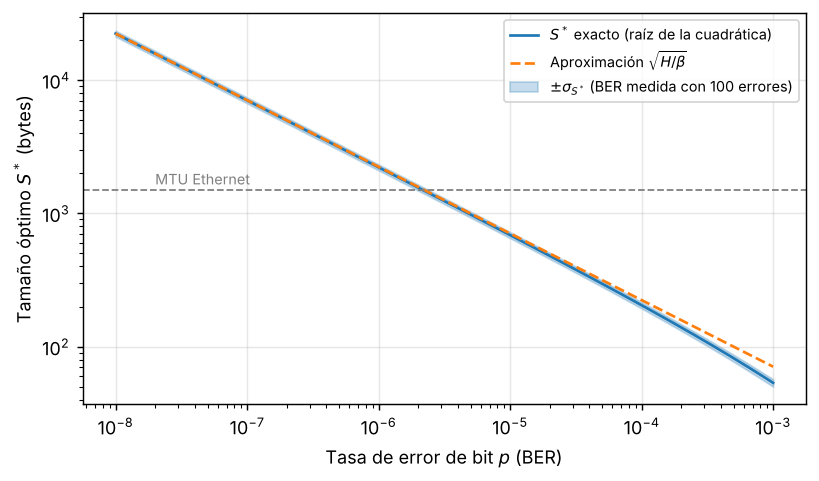

BER = 1e-5 ± 10 %:  S* = 687 ± 35 B (linealización)
                    S* = 690 ± 36 B (Monte Carlo sobre p)
MTU 1500 B es óptimo exactamente para BER ≈ 2.16e-06


In [7]:
def dSopt_dbeta(beta, H=H):
    return -H / (beta**2 * np.sqrt(H**2 + 4 * H / beta))

# Medición hipotética: 100 errores contados -> incertidumbre relativa 10 % en p
k_err = 100
p_grid = np.logspace(-8, -3, 300)
b_grid = beta_de(p_grid)
s_grid = S_optimo(b_grid)
sig_p = p_grid / np.sqrt(k_err)
sig_b = 8 / (1 - p_grid) * sig_p
sig_s = np.abs(dSopt_dbeta(b_grid)) * sig_b

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.loglog(p_grid, s_grid, "C0", label="$S^*$ exacto (raíz de la cuadrática)")
ax.loglog(p_grid, S_aprox(b_grid), "C1--", label="Aproximación $\\sqrt{H/\\beta}$")
ax.fill_between(p_grid, s_grid - sig_s, s_grid + sig_s, color="C0", alpha=0.25,
                label="$\\pm\\sigma_{S^*}$ (BER medida con 100 errores)")
ax.axhline(1500, ls="--", c="gray", lw=1)
ax.text(2e-8, 1650, "MTU Ethernet", fontsize=8, color="gray")
ax.set_xlabel("Tasa de error de bit $p$ (BER)")
ax.set_ylabel("Tamaño óptimo $S^*$ (bytes)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figuras/fig3_sensibilidad.png", dpi=200)
plt.show()

# Verificación de la propagación lineal con Monte Carlo sobre p
b0 = beta_de(p_ref)
p_samp = rng.normal(p_ref, p_ref / np.sqrt(k_err), 200_000)
p_samp = p_samp[p_samp > 0]
s_samp = S_optimo(beta_de(p_samp))
sig_lin = abs(dSopt_dbeta(b0)) * 8 / (1 - p_ref) * p_ref / np.sqrt(k_err)
print(f"BER = 1e-5 ± 10 %:  S* = {S_optimo(b0):.0f} ± {sig_lin:.0f} B (linealización)")
print(f"                    S* = {s_samp.mean():.0f} ± {s_samp.std():.0f} B (Monte Carlo sobre p)")

# BER que hace óptimo el MTU de 1500 B: resolver S*(beta) = 1500 -> beta = H / (S(S+H))
b1500 = H / (1500 * 1540)
p1500 = 1 - np.exp(-b1500 / 8)
print(f"MTU 1500 B es óptimo exactamente para BER ≈ {p1500:.2e}")

## 6. Efecto del tamaño del encabezado

Con encabezados más grandes (p. ej. IPv6 + TCP = 60 B, o túneles VPN) conviene usar paquetes más grandes, porque el costo fijo se reparte entre más datos.

In [8]:
for Hx in [28, 40, 60, 100]:   # UDP/IPv4, TCP/IPv4, TCP/IPv6, túnel
    print(f"H = {Hx:3d} B  ->  S* = {S_optimo(b_ref, Hx):6.1f} B,  E(S*) = {eficiencia(S_optimo(b_ref, Hx), b_ref, Hx):.4f}")

H =  28 B  ->  S* =  577.8 B,  E(S*) = 0.9087
H =  40 B  ->  S* =  687.4 B,  E(S*) = 0.8916
H =  60 B  ->  S* =  836.5 B,  E(S*) = 0.8685
H = 100 B  ->  S* = 1069.1 B,  E(S*) = 0.8328
